# ARGUS Simulation Results
**Federated learning, frame rate under training, and poisoning resistance**

Prepared for the sponsor and team. Code cells are collapsed. Every number below is produced by the
simulator in `sim/` on the `feat/fine-taxonomy` branch, and the notebook re-runs end to end.

In [1]:
import subprocess, datetime
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip()
branch = subprocess.run(["git", "branch", "--show-current"], capture_output=True, text=True).stdout.strip()
print(f"Run {datetime.date.today()}  |  branch {branch} @ {commit}")

Run 2026-10-04  |  branch feat/fine-taxonomy @ f6d0b73


## Summary

| Question | Short answer |
|---|---|
| Does FL beat a node training alone? | **Yes for small data and new cameras. No for a mature site using the shared model as-is.** The winner at every data size is **federated + a short local fine-tune**, which matches or beats local-only from 50 events upward. |
| What does a brand-new camera get? | The fleet model works on day one: **0.78 balanced accuracy and 0.73 anomaly recall with zero local events**, against 0.10 untrained. Local-only needs about 150 events to catch up on accuracy and about 1,500 to catch up on anomaly recall. |
| Does detection keep running during training? | **Yes on the target build:** pi5-hailo and the pipelined build both stay above the 12 FPS target during a real Flower round (Section 2 table). It **does not hold 12 FPS** if the threat model stays on the CPU, and the crop classifier leaves the serial loop with little or no headroom. |
| Can one bad camera poison the fleet? | **Yes with today's FedAvg server.** One crashed node destroys the model; one hostile node can cut anomaly recall from 0.64 to 0.11. **robust.py stops every loud attack tested**, at no accuracy cost, but it is not wired into the server yet, and a quiet label-flip attack still gets through every defence. |

## What is being simulated

**The federated model is not the detector.** YOLO stays frozen and finds person / vehicle / animal / package.
The federated part is a small head (205,445 parameters, 19 inputs) that decides whether a detection is
**routine for this site** or an **anomaly**. A delivery van at 14:00 is routine, and the same van at 03:00 is not.

Three simulated camera sites have different traffic and different rules for what counts as abnormal:

| Site | Mostly sees | What is abnormal there |
|---|---|---|
| driveway | vehicles, residents | anything at night, loitering |
| backdoor | packages, staff | any vehicle, at any hour |
| yard | animals | people at night |

The two headline metrics:
- **Balanced accuracy:** average accuracy across the 5 labels, so rare labels count as much as common ones.
- **Anomaly recall:** of the events that really were abnormal, the share the head flagged. This is the security number.

All accuracy results are averaged over 3 random seeds. Error bars show the spread between seeds.

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "sim").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "sim" / "report"))
import experiments as ex

SEEDS = (1, 2, 3)
import os
# run_report.py --reuse-fps sets this to 0 to reuse the cached frame-rate runs in sim/_run
REFRESH_FPS = os.environ.get("ARGUS_REFRESH_FPS", "1") == "1"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
ARM_STYLE = {
    "untrained": dict(color="#9e9e9e", ls=":"),
    "local only": dict(color="#1f77b4"),
    "federated": dict(color="#d62728"),
    "federated + local fine-tune": dict(color="#2ca02c", lw=2.5),
    "fleet model as-is": dict(color="#d62728"),
    "fleet model + local fine-tune": dict(color="#2ca02c", lw=2.5),
}


def curve_plot(df, x, arms, title, xlabel, logx=True):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, metric, label in zip(axes, ["balanced_acc", "anomaly_recall"], ["Balanced accuracy", "Anomaly recall"]):
        for arm in arms:
            g = df[df.arm == arm].groupby(x)[metric]
            m, s = g.mean(), g.std().fillna(0)
            ax.errorbar(m.index, m.values, yerr=s.values, marker="o", capsize=3, label=arm, **ARM_STYLE[arm])
        ax.set(title=f"{title}: {label.lower()}", xlabel=xlabel, ylabel=label, ylim=(0, 1))
        if logx:
            xs = sorted(df[x].unique())
            ax.set_xscale("symlog", linthresh=50)
            ax.set_xticks(xs, [str(v) for v in xs])
            ax.set_xlim(xs[0] - 10 if xs[0] == 0 else xs[0] * 0.8, xs[-1] * 1.25)
    axes[0].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


def mean_table(df, index, columns="arm", metric="balanced_acc"):
    return df.pivot_table(index=index, columns=columns, values=metric, aggfunc="mean").round(3)

## 1. Does federated learning beat a node training alone?
This is the sponsor's question. Each site's head is obtained four ways:

| Arm | How the head is trained |
|---|---|
| untrained | random weights (the floor) |
| local only | trains on its own events only, and never shares |
| federated | FedAvg across the 3 sites, 6 rounds; every site runs the same global model |
| federated + local fine-tune | the federated model, then a short training pass on the site's own events |

Local-only gets the same number of local training epochs as federated + fine-tune ends up with, so it does not
lose by training less. The federated arms still learn from 3 sites' data instead of 1; that is the point of federating.

### 1a. Same amount of data at every site

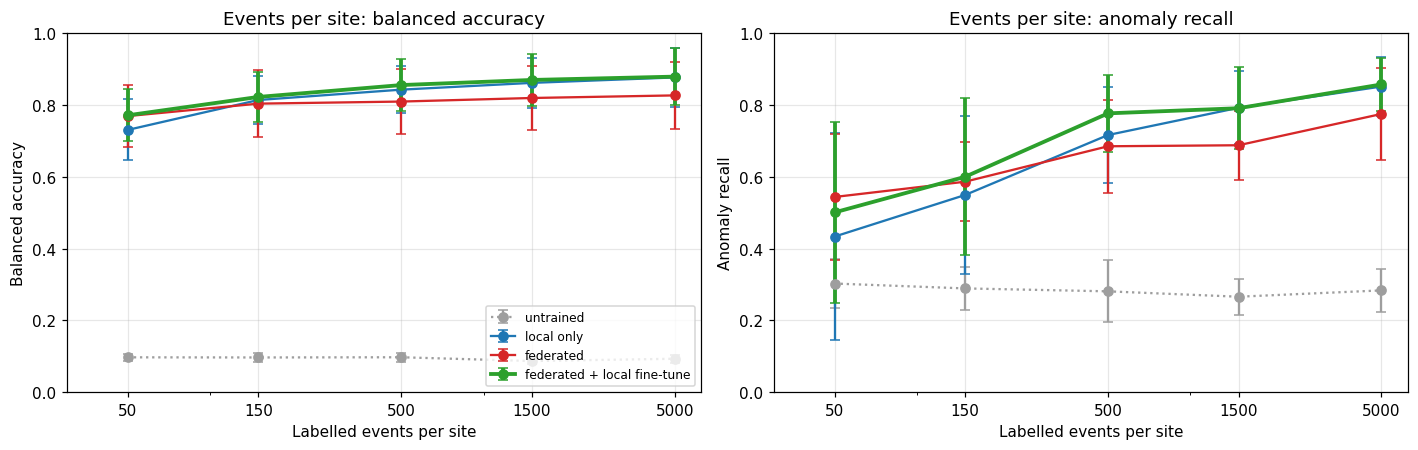

Balanced accuracy (mean of sites and seeds)


arm,untrained,local only,federated,federated + local fine-tune
n_per_site,,,,
50,0.097,0.731,0.769,0.771
150,0.097,0.814,0.804,0.822
500,0.097,0.843,0.810,0.855
1500,0.087,0.862,0.819,0.870
5000,0.093,0.877,0.827,0.879


Anomaly recall


arm,untrained,local only,federated,federated + local fine-tune
n_per_site,,,,
50,0.303,0.433,0.544,0.501
150,0.289,0.549,0.586,0.600
500,0.281,0.716,0.685,0.777
1500,0.266,0.792,0.688,0.791
5000,0.284,0.851,0.775,0.857


In [3]:
fl = pd.DataFrame(ex.fl_vs_local(sizes=[50, 150, 500, 1500, 5000], seeds=SEEDS))
ARMS = ["untrained", "local only", "federated", "federated + local fine-tune"]
curve_plot(fl, "n_per_site", ARMS, "Events per site", "Labelled events per site")
print("Balanced accuracy (mean of sites and seeds)")
display(mean_table(fl, "n_per_site")[ARMS])
print("Anomaly recall")
display(mean_table(fl, "n_per_site", metric="anomaly_recall")[ARMS])

In [4]:
# Per-site view at a realistic first-month volume: where does the shared model hurt?
display(fl[fl.n_per_site == 500].pivot_table(index="site", columns="arm", values="balanced_acc").round(3)[ARMS])

arm,untrained,local only,federated,federated + local fine-tune
site,,,,
backdoor,0.101,0.757,0.698,0.759
driveway,0.084,0.874,0.832,0.895
yard,0.106,0.897,0.898,0.912


### 1b. A new camera joins the fleet
Leave-one-site-out: the fleet trains on two sites (3,000 events each). The third site gets a camera that
the fleet model has **never seen**, with only `local n` events of its own (0 means it was installed today).
This is the day-one experience of a new customer.

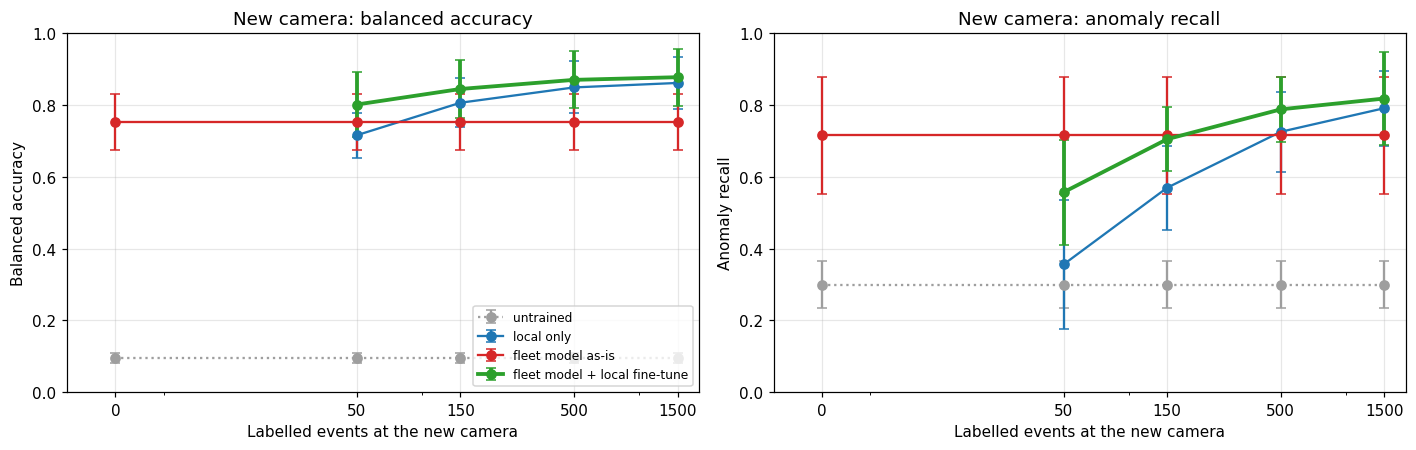

arm,untrained,local only,fleet model as-is,fleet model + local fine-tune
local_n,,,,
0,0.096,NaN,0.752,NaN
50,0.096,0.716,0.752,0.801
150,0.096,0.806,0.752,0.845
500,0.096,0.849,0.752,0.870
1500,0.096,0.861,0.752,0.877


arm,untrained,local only,fleet model as-is,fleet model + local fine-tune
local_n,,,,
0,0.299,NaN,0.715,NaN
50,0.299,0.356,0.715,0.557
150,0.299,0.570,0.715,0.705
500,0.299,0.725,0.715,0.788
1500,0.299,0.791,0.715,0.818


In [5]:
cs = pd.DataFrame(ex.cold_start(local_sizes=[0, 50, 150, 500, 1500], seeds=SEEDS))
CS_ARMS = ["untrained", "local only", "fleet model as-is", "fleet model + local fine-tune"]
curve_plot(cs, "local_n", CS_ARMS, "New camera", "Labelled events at the new camera")
display(mean_table(cs, "local_n").reindex(columns=CS_ARMS))
display(mean_table(cs, "local_n", metric="anomaly_recall").reindex(columns=CS_ARMS))

### 1c. Fine taxonomy (carrier, make, package size) and the household-car problem
This re-runs `sim/compare_taxonomy.py` across 4 sites (adding `curbside`) and adds the fine-tune arm.
"Household car, night" is the resident's own car arriving late. A shared model cannot know whose car
it is, so this slice tests whether site-specific knowledge survives federation.

In [6]:
tx_raw = pd.DataFrame(ex.taxonomy_with_finetune(accs=[1.0, 0.88, 0.76], seeds=SEEDS))
cols = ["balanced accuracy", "household car, night", "stranger car, night",
        "carrier truck, out of window", "usps regular mail"]
tx = tx_raw.groupby(["classifier_acc", "taxonomy", "arm"], as_index=False)[cols].mean()
display(tx.set_index(["classifier_acc", "taxonomy", "arm"])[cols].round(3))
print("Validation events per slice, summed over 4 sites (mean per seed). Small slices swing a lot:")
display(tx_raw.groupby("seed")[[f"n: {c}" for c in cols[1:]]].first().mean().round(0).astype(int).to_frame("events"))

balanced accuracy  \
classifier_acc taxonomy arm                                              
0.76           coarse   federated                                0.868   
                        federated + local fine-tune              0.921   
                        local only                               0.922   
               fine     federated                                0.897   
                        federated + local fine-tune              0.944   
                        local only                               0.932   
0.88           coarse   federated                                0.868   
                        federated + local fine-tune              0.921   
                        local only                               0.922   
               fine     federated                                0.906   
                        federated + local fine-tune              0.953   
                        local only                               0.949   
1.00           coarse   federated                                0.868   
                        federated + local fine-tune              0.921   
                        local only                               0.922   
               fine     federated                                0.913   
                        federated + local fine-tune              0.968   
                        local only                               0.961   

                                                     household car, night  \
classifier_acc taxonomy arm                                                 
0.76           coarse   federated                                   0.000   
                        federated + local fine-tune                 0.412   
                        local only                                  0.400   
               fine     federated                                   0.035   
                        federated + local fine-tune                 0.825   
                        local only                                  0.811   
0.88           coarse   federated                                   0.000   
                        federated + local fine-tune                 0.412   
                        local only                                  0.400   
               fine     federated                                   0.018   
                        federated + local fine-tune                 0.881   
                        local only                                  0.881   
1.00           coarse   federated                                   0.000   
                        federated + local fine-tune                 0.412   
                        local only                                  0.400   
               fine     federated                                   0.014   
                        federated + local fine-tune                 1.000   
                        local only                                  0.971   

                                                     stranger car, night  \
classifier_acc taxonomy arm                                                
0.76           coarse   federated                                  0.963   
                        federated + local fine-tune                0.663   
                        local only                                 0.617   
               fine     federated                                  0.918   
                        federated + local fine-tune                0.712   
                        local only                                 0.635   
0.88           coarse   federated                                  0.963   
                        federated + local fine-tune                0.663   
                        local only                                 0.617   
               fine     federated                                  0.890   
                        federated + local fine-tune                0.715   
                        local only         

Validation events per slice, summed over 4 sites (mean per seed). Small slices swing a lot:


,events
"n: household car, night",20
"n: stranger car, night",32
"n: carrier truck, out of window",111
n: usps regular mail,120


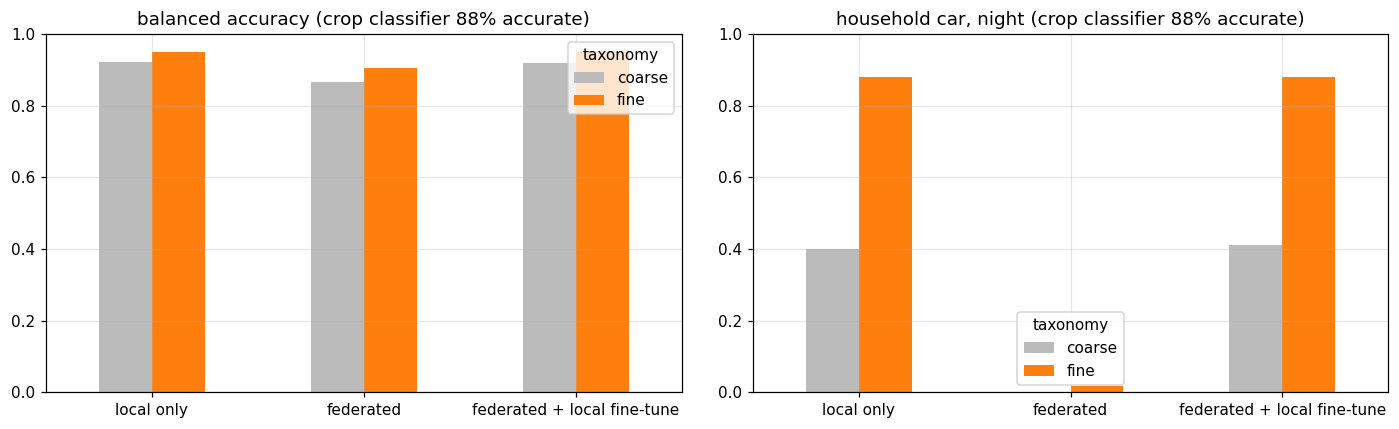

In [7]:
sub = tx[tx.classifier_acc == 0.88]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["balanced accuracy", "household car, night"]):
    sub.pivot(index="arm", columns="taxonomy", values=metric).loc[
        ["local only", "federated", "federated + local fine-tune"]].plot.bar(ax=ax, rot=0, color=["#bbbbbb", "#ff7f0e"])
    ax.set(title=f"{metric} (crop classifier 88% accurate)", ylim=(0, 1), xlabel="")
plt.tight_layout()
plt.show()

## 2. Does a node keep detecting while it trains?
`sim/run_node.py` runs the detection loop at 12 FPS. A **real Flower round** (gRPC, separate OS processes,
5 rounds x 12 epochs on 20,000 events) runs alongside it, pinned to 4 cores like a Pi 5. Frame rate is measured
in three phases: before, during, and after training.

| Configuration | Meaning |
|---|---|
| pi5-hailo | target build: YOLO + threat model on the Hailo, serial loop |
| pi5-hailo pipelined | same, with the Hailo overlapped with CPU work |
| pi5-hailo-fine | target build plus the carrier/make/size crop classifier |
| pi5-threat-on-cpu | risk case: the threat model never gets compiled for the Hailo |
| pi5-cpu-only | fallback: the Hailo is missing or fails its probe |

Hailo and CPU stage times are budgets from Proposal Rev 2.2 Table 11. They are **not Pi measurements**.

In [8]:
FPS_RUNS = {
    "pi5-hailo": ["--profile", "pi5-hailo"],
    "pi5-hailo pipelined": ["--profile", "pi5-hailo", "--pipelined"],
    "pi5-hailo-fine": ["--profile", "pi5-hailo-fine", "--taxonomy", "fine"],
    "pi5-threat-on-cpu": ["--profile", "pi5-threat-on-cpu"],
    "pi5-cpu-only": ["--profile", "pi5-cpu-only"],
}
fps = {name: ex.run_fps(name.replace(" ", "_"), args, refresh=REFRESH_FPS) for name, args in FPS_RUNS.items()}
fps_df = pd.DataFrame([
    {"configuration": n, "phase": ph, **v}
    for n, r in fps.items() for ph, v in r["phases"].items()
])
tbl = fps_df.pivot(index="configuration", columns="phase", values="fps")[["baseline", "fl", "recovery"]]
tbl["change during training"] = ((tbl["fl"] - tbl["baseline"]) / tbl["baseline"] * 100).round(1).astype(str) + "%"
tbl["p95 ms during training"] = fps_df[fps_df.phase == "fl"].set_index("configuration")["p95"]
tbl["holds 12 FPS while training"] = np.where(tbl["fl"] >= 12, "yes", "NO")
display(tbl.loc[list(FPS_RUNS)].round(2))

phase,baseline,fl,recovery,change during training,p95 ms during training,holds 12 FPS while training
configuration,,,,,,
pi5-hailo,12.08,12.98,13.48,7.5%,106.7,yes
pi5-hailo pipelined,24.42,24.27,24.81,-0.6%,45.8,yes
pi5-hailo-fine,13.37,13.34,13.39,-0.2%,75.6,yes
pi5-threat-on-cpu,10.81,10.29,9.57,-4.8%,125.1,NO
pi5-cpu-only,2.37,2.38,2.39,0.4%,456.8,NO


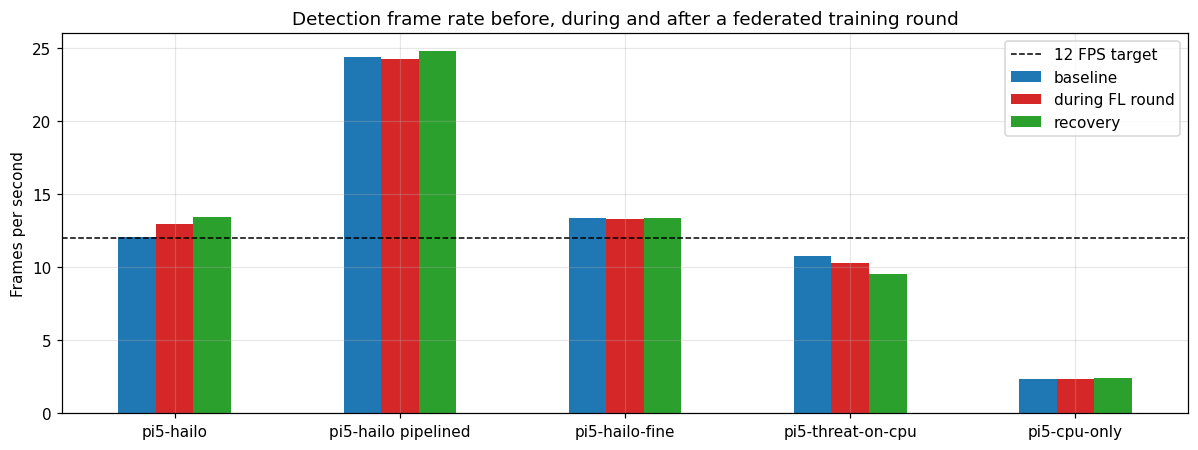

In [9]:
ax = fps_df.pivot(index="configuration", columns="phase", values="fps").loc[list(FPS_RUNS), ["baseline", "fl", "recovery"]] \
    .rename(columns={"fl": "during FL round"}).plot.bar(figsize=(11, 4.2), rot=0, color=["#1f77b4", "#d62728", "#2ca02c"])
ax.axhline(12, color="k", ls="--", lw=1, label="12 FPS target")
ax.set(title="Detection frame rate before, during and after a federated training round", ylabel="Frames per second", xlabel="")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Can one bad camera poison the fleet?
A 6-camera fleet (2 per site) trains for 6 rounds. One driveway camera sends a bad update **every round**.
The attacks:

| Attack | What the bad camera sends |
|---|---|
| none | honest update (control) |
| NaN (diverged node) | a crashed or diverged trainer: all NaN |
| random noise | garbage weights |
| sign flip x4 | its real update reversed and amplified, to drag the model backwards |
| label flip (hide anomalies) | trained honestly, but on data where every anomaly is labelled routine (a quiet, targeted attack) |
| label flip, boosted x2.5 | the same, scaled just under robust.py's norm limit (a careful attacker) |
| label flip, boosted x6 | the same, scaled up to take over the average (model replacement) |

Server-side defences:
- **FedAvg:** what the Flower server runs today.
- **Trimmed mean:** drop the highest and lowest value of each weight, then average.
- **robust.py:** `src/federated/robust.py` with its shipped default settings. Written and tested, but **not yet wired into the server**.
- **robust.py + validation gate:** also refuses a new model whose balanced accuracy drops on a small server-side
  holdout (600 events the nodes never train on and the final score never uses).

In [10]:
ATTACKS = ["none", "NaN (diverged node)", "random noise", "sign flip x4",
           "label flip (hide anomalies)", "label flip, boosted x2.5", "label flip, boosted x6"]
STRATS = ["FedAvg", "trimmed mean", "robust.py", "robust.py + validation gate"]
rb = pd.DataFrame(ex.robustness(ATTACKS, seeds=SEEDS))
for metric, label in [("anomaly_recall", "Anomaly recall"), ("balanced_acc", "Balanced accuracy")]:
    print(label + " of the fleet model after 6 rounds (0.000 = model destroyed)")
    display(rb.pivot_table(index="attack", columns="strategy", values=metric).loc[ATTACKS, STRATS].round(3))

Anomaly recall of the fleet model after 6 rounds (0.000 = model destroyed)


strategy,FedAvg,trimmed mean,robust.py,robust.py + validation gate
attack,,,,
none,0.637,0.642,0.635,0.635
NaN (diverged node),0.000,0.649,0.669,0.669
random noise,0.665,0.649,0.669,0.669
sign flip x4,0.978,0.743,0.669,0.669
label flip (hide anomalies),0.568,0.573,0.560,0.560
"label flip, boosted x2.5",0.448,0.575,0.449,0.416
"label flip, boosted x6",0.075,0.573,0.669,0.669


Balanced accuracy of the fleet model after 6 rounds (0.000 = model destroyed)


strategy,FedAvg,trimmed mean,robust.py,robust.py + validation gate
attack,,,,
none,0.859,0.862,0.859,0.859
NaN (diverged node),0.000,0.847,0.836,0.836
random noise,0.839,0.844,0.836,0.836
sign flip x4,0.356,0.772,0.836,0.836
label flip (hide anomalies),0.873,0.872,0.875,0.875
"label flip, boosted x2.5",0.877,0.873,0.877,0.871
"label flip, boosted x6",0.798,0.875,0.836,0.836


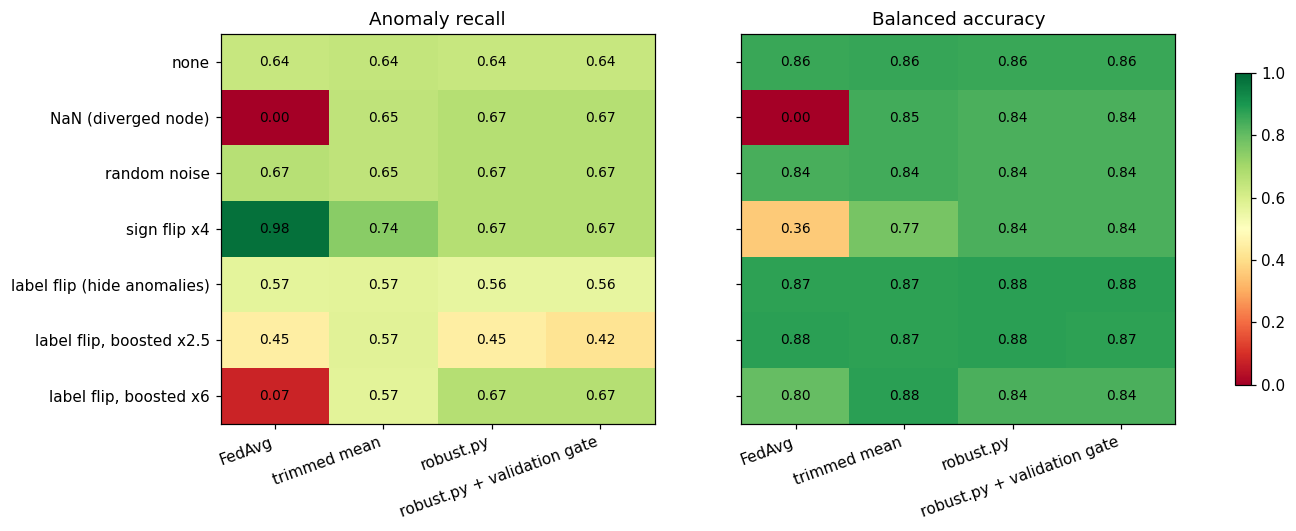

Rounds (of 6) in which robust.py rejected the bad camera, and honest updates it wrongly rejected (of 30):


attacker_rejected_rounds  \
strategy                                   robust.py   
attack                                                 
none                                             0.0   
NaN (diverged node)                              6.0   
random noise                                     6.0   
sign flip x4                                     6.0   
label flip (hide anomalies)                      0.0   
label flip, boosted x2.5                         0.0   
label flip, boosted x6                           6.0   

                                                        honest_rejections  \
strategy                    robust.py + validation gate         robust.py   
attack                                                                      
none                                                0.0               0.0   
NaN (diverged node)                                 6.0               0.0   
random noise                                        6.0               0.0   
sign flip x4                                        6.0               0.0   
label flip (hide anomalies)                         0.0               0.0   
label flip, boosted x2.5                            0.0               0.0   
label flip, boosted x6                              6.0               0.0   

                                                         
strategy                    robust.py + validation gate  
attack                                                   
none                                                0.0  
NaN (diverged node)                                 0.0  
random noise                                        0.0  
sign flip x4                                        0.0  
label flip (hide anomalies)                         0.0  
label flip, boosted x2.5                            0.0  
label flip, boosted x6                              0.0

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, metric, label in zip(axes, ["anomaly_recall", "balanced_acc"], ["Anomaly recall", "Balanced accuracy"]):
    piv = rb.pivot_table(index="attack", columns="strategy", values=metric).loc[ATTACKS, STRATS]
    im = ax.imshow(piv.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(STRATS)), STRATS, rotation=20, ha="right")
    ax.set_yticks(range(len(ATTACKS)), ATTACKS)
    ax.grid(False)
    for i in range(len(ATTACKS)):
        for j in range(len(STRATS)):
            ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(label)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

rob = rb[rb.strategy.str.startswith("robust")]
print("Rounds (of 6) in which robust.py rejected the bad camera, and honest updates it wrongly rejected (of 30):")
display(rob.groupby(["attack", "strategy"])[["attacker_rejected_rounds", "honest_rejections"]].mean()
        .unstack().loc[ATTACKS].round(1))

## Findings and recommendations

### 1. Federated learning vs local-only
- **The shared model alone plateaus.** Federated balanced accuracy stays around 0.81 regardless of data volume, while local-only climbs to 0.875 at 5,000 events per site. The sites disagree about what is abnormal (a vehicle is routine on the driveway and always wrong at the back door), and one averaged model cannot hold every site's rule. The per-site table shows the cost falls mostly on the back door (0.70 federated vs 0.76 local).
- **Federation wins when data is scarce.** At 50 events per site, the federated model beats local-only on balanced accuracy (0.77 vs 0.73) and on anomaly recall (0.56 vs 0.44). A month-one camera has exactly this little data.
- **Federated + local fine-tune is the best of both.** It is the top arm from 150 events upward (0.826 to 0.879 balanced accuracy) and has the best anomaly recall from 500 events upward. At 50 events, the plain federated model still has the best recall, so fine-tuning should wait until a site has a few hundred labelled events.
- **Cold start is the strongest argument for FL.** A camera at a site the fleet has never seen gets 0.78 balanced accuracy and 0.73 anomaly recall on its first day. Local-only needs about 150 events to match the accuracy and about 1,500 to match the recall. Fine-tuning the fleet model is the best option at every local data size.

### 1c. Fine taxonomy and site identity
- The fine taxonomy (carrier, make, package size) raises balanced accuracy for every training method: +0.03 to +0.05 with a crop classifier that is 88% accurate, and still positive at 76%.
- **A shared model cannot learn "this is the resident's car."** Federated scores 0.00 to 0.11 on household cars at night. Local fine-tuning with the fine taxonomy restores this to 0.95 to 1.00. Site-specific fine-tuning is needed for this feature to work at all.
- **Trade-off:** fine-tuning makes a site forget some fleet knowledge about events it rarely sees. "Carrier truck out of its delivery window" falls from 0.97 (federated) to 0.72 after fine-tuning, and "stranger car at night" falls from 0.92 to 0.84. Fine-tuning needs a guard against this, such as fewer epochs, keeping the fleet model's anomaly flags as a second opinion, or regularizing toward the fleet weights.

### 2. Frame rate while training
- **Target build:** pi5-hailo (about 14.5 FPS ceiling) and the pipelined build (about 25 FPS ceiling) stay above 12 FPS while a real Flower round trains next to them. Training a 205K-parameter head on the CPU does not stop detection when the Hailo does the heavy work.
- **Below target or marginal:** pi5-threat-on-cpu is below 12 FPS before training even starts (about 11 FPS ceiling). pi5-hailo-fine has about 13 FPS of ceiling, so any contention during training can push it under target. The CPU-only fallback runs at about 2.5 FPS either way.
- **Read the percentages with care.** This simulator measures on the PC it runs on, so anything else using the CPU (a browser, a sync client) shows up as a training cost. Two runs on 2026-10-04 measured pi5-hailo at +0.1% and -8.1% during training. If the recovery phase does not return to the baseline, the drop was background load, not training. Which builds pass or fail 12 FPS was consistent across runs. The numbers that matter will come from a Pi 5.

### 3. Poisoning resistance
- **FedAvg (what the server runs today) is fragile.** One node sending NaN wipes the fleet model completely (0.00). A sign-flipped update drops balanced accuracy to 0.24. Its 1.00 anomaly recall in the heatmap is not a good result: the model flags nearly everything as an anomaly, which makes the alerts useless. A boosted "hide anomalies" update cuts anomaly recall from 0.64 to 0.11, meaning nearly 9 in 10 real anomalies would no longer be flagged on every camera.
- **robust.py stops every loud attack tested.** It rejected the bad camera in 6 of 6 rounds for the NaN, noise, sign-flip and boosted attacks. With no attack it costs nothing (0.866 vs 0.863 balanced accuracy). Plain trimmed mean survives NaN but still lets a sign-flip through (anomaly recall pushed to 0.77 at the cost of balanced accuracy 0.78).
- **The quiet attack gets through.** An unboosted "hide anomalies" camera looks like an honest one in norm and direction, so robust.py never rejected it. Anomaly recall fell from 0.64 to 0.59 under every defence. The validation gate did not catch it either, because it only checks balanced accuracy, and balanced accuracy barely moved (0.877).

### Recommendations
1. **Ship federated + per-site fine-tune, and start new cameras on the fleet model.** Gate fine-tuning on having a few hundred labelled events, and protect against forgetting rare fleet-learned anomalies.
2. **Wire robust.py into `central_server/fl_aggregator.py` before any multi-site trial.** Under FedAvg, a single crashed node takes the whole fleet down.
3. **Make the validation gate check anomaly recall, not just balanced accuracy.** Combined with the loss tie-break already on the to-do list, this is the cheapest defence against the quiet label-flip attack.
4. **Compile the threat model for the Hailo, and pipeline the loop before adding the crop classifier.** Both failing configurations are timing problems the pipelined build has headroom for.
5. **Replace the Table 11 budgets with Pi 5 + Hailo measurements** (`scripts/benchmark_classes.py`, then `sim/profiles.py`), and re-run Section 2 on the Pi itself.

## What this does not show
- **Synthetic events.** Site traffic, delivery windows, and anomaly rules are simulation assumptions. No real ARGUS footage is used.
  The 2026-09-20 hardware run (322 labelled events, balanced accuracy 0.75) is the only real-data point so far.
- **Frame-rate budgets, not Pi measurements.** The stage times come from Proposal Rev 2.2 Table 11. No Pi 5 + Hailo benchmark exists in the repo yet.
- **This machine's cores, not a Pi's.** Pinning to 4 cores matches the core count, not the per-core speed.
- **In-process federation for the accuracy studies.** It uses the same FedAvg maths as the Flower server, without the network.
  Section 2 uses the real Flower gRPC path.
- **Attacks are simple.** A patient attacker who stays just under the norm limit and agrees with the consensus direction is
  harder to stop. Section 3 shows the quiet label flip is already one of these.